# Transformer-to-VLA

## Vision Transformers

### 从零构建 Vision Transformer

---

**目标**

理解图像如何转换为 Visual Tokens，以及 Transformer Encoder 如何处理这些 Token。

**核心概念**

- Image Patch Embedding
- Patch Tokens
- CLS Token
- Positional Embedding
- Vision Transformer Encoder
- Visual Representation Learning

**实现**

本 Notebook 使用 PyTorch 构建一个最小 Vision Transformer，并分析图像转换为 Token 序列的过程。

**学习重点**

理解 Transformer 架构如何从语言建模扩展到视觉表征学习。

In [1]:
import math, random
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device, '| torch:', torch.__version__)

device: cuda | torch: 2.14.1+cu130


## 1. 制造可控的图像数据

每张图随机出现横向或纵向条纹，加入噪声与位置偏移。标签 `0=horizontal`，`1=vertical`。这让我们可以独立观察视觉 Token 的处理过程，不依赖 MNIST 下载。

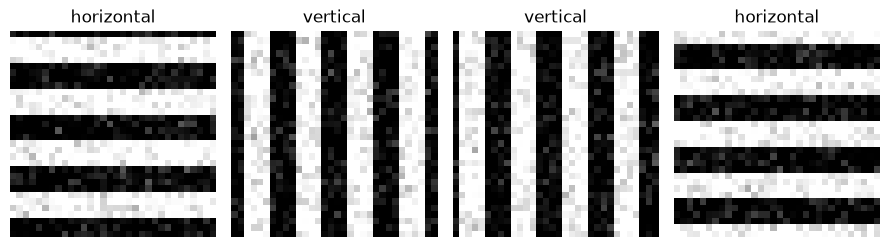

In [2]:
def make_stripes(n=800, size=32, noise=0.12):
    xy = torch.arange(size)
    images, labels = [], []
    for _ in range(n):
        label = int(torch.randint(0, 2, ()).item())
        offset = int(torch.randint(0, 8, ()).item())
        row = (((xy + offset) // 4) % 2).float()
        base = row[:, None].expand(size, size) if label == 0 else row[None, :].expand(size, size)
        img = (base + noise * torch.randn(size, size)).clamp(0, 1)
        images.append(img.unsqueeze(0)); labels.append(label)
    return torch.stack(images), torch.tensor(labels)

X, y = make_stripes()
train_loader = DataLoader(TensorDataset(X[:640], y[:640]), batch_size=64, shuffle=True)
test_loader = DataLoader(TensorDataset(X[640:], y[640:]), batch_size=64)
fig, axes = plt.subplots(1, 4, figsize=(9, 2.5))
for i, ax in enumerate(axes):
    ax.imshow(X[i, 0], cmap='gray', vmin=0, vmax=1)
    ax.set_title(['horizontal', 'vertical'][y[i].item()]); ax.axis('off')
plt.tight_layout(); plt.show()

## 2. Patch Embedding

输入张量 `B×1×32×32`。选择 `P=8`，图像被划成 `(32/8)²=16` 个 patch。

每个 patch 包含 `1×8×8=64` 个数，线性映射到隐藏维度 `D=64`。可使用 `nn.Conv2d(kernel_size=P, stride=P)`，等价于对每个不重叠 patch 应用**共享的线性投影**：

$$
Z_{\mathrm{patch}} = \operatorname{Flatten}(\operatorname{Patchify}(I))W_E+b_E
$$

输出形状：`B×16×64`。

这里的 Flatten 只展平每个 patch 内的像素，保留批次和 patch 序列维；概念上的 $W_E\in\mathbb R^{(P^2C)\times D}$。


In [3]:
class PatchEmbedding(nn.Module):
    def __init__(self, image_size=32, patch_size=8, in_channels=1, dim=64):
        super().__init__()
        assert patch_size > 0 and image_size % patch_size == 0
        self.image_size = image_size
        self.grid_size = image_size // patch_size
        self.num_patches = self.grid_size ** 2
        self.proj = nn.Conv2d(in_channels, dim, kernel_size=patch_size, stride=patch_size)
    def forward(self, x):
        if x.shape[-2:] != (self.image_size, self.image_size):
            raise ValueError("Input image size must match the configured image_size")
        return self.proj(x).flatten(2).transpose(1, 2)

patch_embed = PatchEmbedding()
tokens = patch_embed(X[:2])
print('Image:', X[:2].shape, '→ Patch tokens:', tokens.shape)
assert tokens.shape == (2, 16, 64)

Image: torch.Size([2, 1, 32, 32]) → Patch tokens: torch.Size([2, 16, 64])


## 3. CLS Token + Position Embedding + Transformer Encoder

`[CLS]` 是额外的可学习 Token，参与所有 Token 的 Self-Attention；最后读取它的输出进行分类。

$$
Z_0 = [z_{\mathrm{cls}}; Z_{\mathrm{patch}}]+ E_{\mathrm{pos}}
$$

这里使用 PyTorch 的 `nn.MultiheadAttention` 实现标准多头注意力，用残差连接、LayerNorm 和前馈网络搭建完整的 Encoder Block；不依赖任何预训练 ViT 库。

In [4]:
class EncoderBlock(nn.Module):
    def __init__(self, dim=64, heads=4, mlp_ratio=2):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attn = nn.MultiheadAttention(dim, heads, batch_first=True)
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = nn.Sequential(nn.Linear(dim, dim * mlp_ratio), nn.GELU(), nn.Linear(dim * mlp_ratio, dim))
    def forward(self, x, return_attention=False):
        z = self.norm1(x)
        h, weights = self.attn(z, z, z, need_weights=return_attention, average_attn_weights=False)
        x = x + h
        x = x + self.mlp(self.norm2(x))
        return (x, weights) if return_attention else x

class TinyViT(nn.Module):
    def __init__(self, image_size=32, patch_size=8, dim=64, depth=2, heads=4):
        super().__init__()
        self.patches = PatchEmbedding(image_size, patch_size, 1, dim)
        N = self.patches.num_patches
        self.cls_token = nn.Parameter(torch.zeros(1, 1, dim))
        self.position = nn.Parameter(torch.randn(1, N+1, dim) * 0.02)
        self.blocks = nn.ModuleList([EncoderBlock(dim, heads) for _ in range(depth)])
        self.norm = nn.LayerNorm(dim)
        self.head = nn.Linear(dim, 2)
    def forward(self, images, return_attention=False):
        patch_tokens = self.patches(images)
        cls = self.cls_token.expand(images.shape[0], -1, -1)
        x = torch.cat((cls, patch_tokens), dim=1) + self.position
        final_attention = None
        for block in self.blocks:
            if return_attention:
                x, final_attention = block(x, return_attention=True)
            else:
                x = block(x)
        logits = self.head(self.norm(x[:, 0]))
        return (logits, final_attention) if return_attention else logits

model = TinyViT().to(device)
print('Image → logits:', model(X[:2].to(device)).shape)
print('Params:', sum(p.numel() for p in model.parameters()))

Image → logits: torch.Size([2, 2])
Params: 72514


## 4. 训练和评估

默认 8 个 epoch，适合 CPU 快速运行。`CrossEntropyLoss` 负责两类分类任务。

Epoch 01 | loss 0.7312 | test acc 0.694
Epoch 02 | loss 0.3085 | test acc 1.000
Epoch 03 | loss 0.0206 | test acc 1.000
Epoch 04 | loss 0.0040 | test acc 1.000
Epoch 05 | loss 0.0023 | test acc 1.000
Epoch 06 | loss 0.0017 | test acc 1.000


Epoch 07 | loss 0.0014 | test acc 1.000
Epoch 08 | loss 0.0012 | test acc 1.000


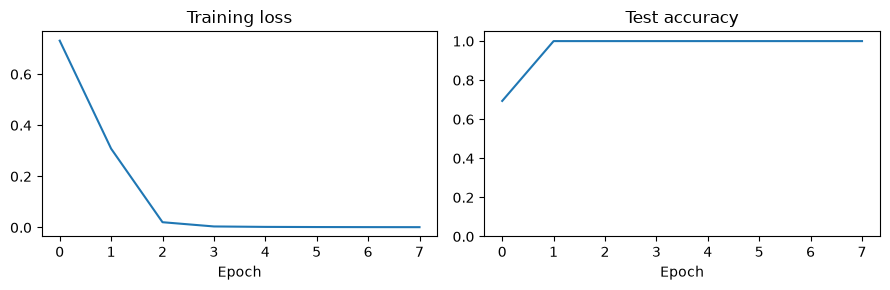

In [5]:
optimizer = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=1e-3)
loss_fn = nn.CrossEntropyLoss()
EPOCHS = 8
train_losses, test_accs = [], []
for epoch in range(EPOCHS):
    model.train(); losses = []
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = loss_fn(model(xb), yb)
        loss.backward(); optimizer.step()
        losses.append(loss.item())
    model.eval(); correct=total=0
    with torch.no_grad():
        for xb, yb in test_loader:
            pred = model(xb.to(device)).argmax(-1).cpu()
            correct += (pred == yb).sum().item(); total += len(yb)
    train_losses.append(np.mean(losses)); test_accs.append(correct/total)
    print(f'Epoch {epoch+1:02d} | loss {train_losses[-1]:.4f} | test acc {test_accs[-1]:.3f}')
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].plot(train_losses); ax[0].set_title('Training loss'); ax[0].set_xlabel('Epoch')
ax[1].plot(test_accs); ax[1].set_ylim(0, 1.05); ax[1].set_title('Test accuracy'); ax[1].set_xlabel('Epoch')
plt.tight_layout(); plt.show()

## 5. 可视化 CLS 对图像 Patch 的 Attention

最后一层的 Attention 权重为 `[B, heads, N+1, N+1]`。默认 `P=8` 时，`N=16`，序列长 17；取第一张图像中 `[CLS]` 对图像 Patch 的权重 `attention[0, :, 0, 1:]`，保留 Head 维，分别恢复成 `grid_size × grid_size` 网格，其中 `grid_size = image_size // patch_size`。每个 Head 单独展示，所有热力图共享颜色范围，便于比较权重大小与空间分布；不对各 Head 求平均，也不对截取后的权重重新归一化。CLS 也可关注自己，因此每个 Head 仅取图像 Patch 后的权重之和不一定为 1。

> 注意：Attention 热力图是权重示意，**不等价于可靠的模型可解释性归因**。

Attention: torch.Size([1, 4, 17, 17]) | predicted label: 0


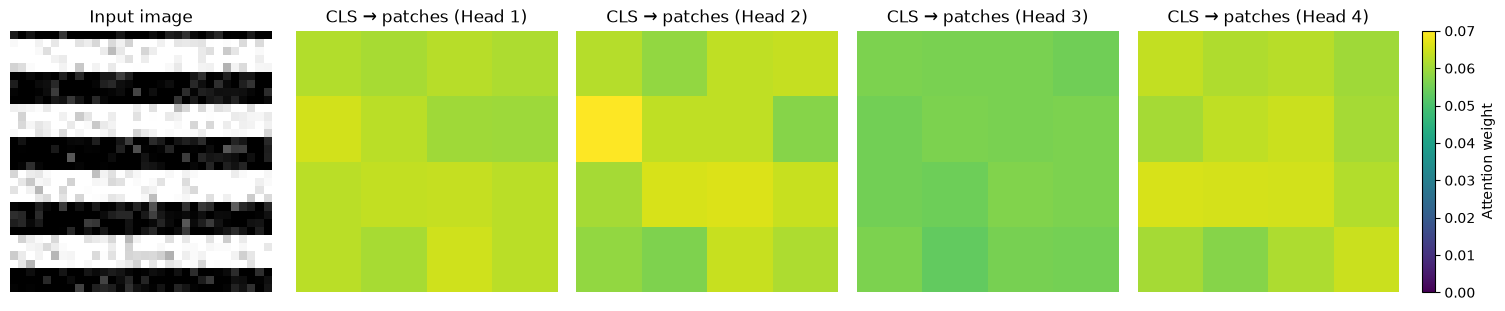

In [6]:
model.eval()
with torch.no_grad():
    logits, attention = model(X[:1].to(device), return_attention=True)
print('Attention:', attention.shape, '| predicted label:', logits.argmax(-1).item())

grid_size = model.patches.grid_size
num_heads = attention.shape[1]
cls_attention = attention[0, :, 0, 1:].reshape(num_heads, grid_size, grid_size).cpu().numpy()
vmax = cls_attention.max()

fig, axs = plt.subplots(1, num_heads + 1, figsize=(3 * (num_heads + 1), 3), constrained_layout=True)
axs[0].imshow(X[0, 0], cmap='gray', vmin=0, vmax=1); axs[0].set_title('Input image')
for h in range(num_heads):
    im = axs[h+1].imshow(cls_attention[h], cmap='viridis', vmin=0, vmax=vmax)
    axs[h+1].set_title(f'CLS → patches (Head {h+1})')
for a in axs: a.axis('off')
fig.colorbar(im, ax=axs[1:].tolist(), fraction=0.015, pad=0.02, label='Attention weight')
plt.show()

## 6. 与 VLA 的关系及练习

ViT 的关键输出并不一定是分类结果。在 VLA 中我们通常**保留 Patch Tokens（或经过视觉主干处理的视觉特征）**，再经过投影或适配进入 VLM。

- 修改 `patch_size=4`，Patch Token 数量变成多少？计算 Attention 序列长度变化。
- 去掉 `position`，比较分类表现。本任务的单个 patch 已含条纹方向信息，因而不能用这个实验断言位置编码无用；研究全局布局需要另外设计依赖 patch 相对位置的数据。
- 为什么分类任务使用 `[CLS]`，但 VLM 往往需要**多个** Visual Tokens？

**下一实验**：[Visual Token Projection](https://github.com/Maple-Ze/Transformer-to-VLA/blob/main/03_Vision_Transformers/02_Visual_Token_Projection.ipynb)，不再输出分类标签，而是把 Visual Tokens 投影并与文本 Token 送入同一个多模态 Attention 层。

参考：[Vision Transformer 原论文](https://arxiv.org/abs/2010.11929)。

[返回项目首页](https://github.com/Maple-Ze/Transformer-to-VLA/blob/main/README.md)
